# Student Performance Analysis

Which factors are linked to a student's exam score, and can we predict that score early enough to help students who are at risk?

**Data:** [Student Performance Factors](https://www.kaggle.com/datasets/lainguyn123/student-performance-factors) (Kaggle), 6,607 students, 19 predictors and 1 target (`Exam_Score`).

| Group | Features |
|---|---|
| Study habits | `Hours_Studied` (per week), `Attendance` (%), `Previous_Scores`, `Tutoring_Sessions` (per month), `Extracurricular_Activities` |
| Health and lifestyle | `Sleep_Hours` (per night), `Physical_Activity` (hours per week) |
| Personal | `Motivation_Level`, `Learning_Disabilities`, `Gender` |
| Family | `Parental_Involvement`, `Parental_Education_Level`, `Family_Income` |
| School and environment | `Teacher_Quality`, `School_Type`, `Peer_Influence`, `Access_to_Resources`, `Internet_Access`, `Distance_from_Home` |

**Research questions**

1. Which factors are most strongly linked to exam scores?
2. Do controllable factors (study hours, attendance) matter more than background factors (income, parental education)?
3. How accurately can a model predict a student's score?
4. Are there unexpected patterns or anomalies in the data?

## Setup

In [1]:
import math
import os
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy import stats

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, cross_val_predict, cross_validate, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

sys.path.append('..')  # so the project's src/ package can be imported
from src.features import ENGINEERED_FEATURES, add_engineered_features

In [2]:
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)

RANDOM_STATE = 42
DATA_PATH = '../data/raw/StudentPerformanceFactors.csv'
MODEL_PATH = '../models/best_model.pkl'


def make_grid(n_plots, n_cols=3, cell_size=(5, 4)):
    n_rows = math.ceil(n_plots / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(cell_size[0] * n_cols, cell_size[1] * n_rows))
    axes = np.atleast_1d(axes).flatten()
    for ax in axes[n_plots:]:
        ax.set_visible(False)
    return fig, axes[:n_plots]

## Load and Inspect the Data

In [3]:
df = pd.read_csv(DATA_PATH)
RAW_ROWS = len(df)
print(f"{df.shape[0]} rows x {df.shape[1]} columns")
df.head(10)

6607 rows x 20 columns


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
5,19,88,Medium,Medium,Yes,8,89,Medium,Yes,3,Medium,Medium,Public,Positive,3,No,Postgraduate,Near,Male,71
6,29,84,Medium,Low,Yes,7,68,Low,Yes,1,Low,Medium,Private,Neutral,2,No,High School,Moderate,Male,67
7,25,78,Low,High,Yes,6,50,Medium,Yes,1,High,High,Public,Negative,2,No,High School,Far,Male,66
8,17,94,Medium,High,No,6,80,High,Yes,0,Medium,Low,Private,Neutral,1,No,College,Near,Male,69
9,23,98,Medium,Medium,Yes,8,71,Medium,Yes,0,High,High,Public,Positive,5,No,High School,Moderate,Male,72


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  Physical_Activity  

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Hours_Studied,6607.0,19.975329,5.990594,1.0,16.0,20.0,24.0,44.0
Attendance,6607.0,79.977448,11.547475,60.0,70.0,80.0,90.0,100.0
Sleep_Hours,6607.0,7.029060,1.468120,4.0,6.0,7.0,8.0,10.0
Previous_Scores,6607.0,75.070531,14.399784,50.0,63.0,75.0,88.0,100.0
Tutoring_Sessions,6607.0,1.493719,1.230570,0.0,1.0,1.0,2.0,8.0
Physical_Activity,6607.0,2.967610,1.031231,0.0,2.0,3.0,4.0,6.0
Exam_Score,6607.0,67.235659,3.890456,55.0,65.0,67.0,69.0,101.0


In [6]:
numerical_cols = df.select_dtypes(include='number').columns.drop('Exam_Score')
categorical_cols = df.select_dtypes(exclude='number').columns

print(f"Numerical ({len(numerical_cols)}): {list(numerical_cols)}")
print(f"Categorical ({len(categorical_cols)}): {list(categorical_cols)}\n")
print("Unique values in categorical columns: ")
for col in categorical_cols:
    print(f" -{col}: {sorted(df[col].dropna().unique())}")

Numerical (6): ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']
Categorical (13): ['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']

Unique values in categorical columns: 
 -Parental_Involvement: ['High', 'Low', 'Medium']
 -Access_to_Resources: ['High', 'Low', 'Medium']
 -Extracurricular_Activities: ['No', 'Yes']
 -Motivation_Level: ['High', 'Low', 'Medium']
 -Internet_Access: ['No', 'Yes']
 -Family_Income: ['High', 'Low', 'Medium']
 -Teacher_Quality: ['High', 'Low', 'Medium']
 -School_Type: ['Private', 'Public']
 -Peer_Influence: ['Negative', 'Neutral', 'Positive']
 -Learning_Disabilities: ['No', 'Yes']
 -Parental_Education_Level: ['College', 'High School', 'Postgraduate']
 -Distance_from_Home: ['Far', 'Modera

In [7]:
CAT_LEVELS = {
    'Parental_Involvement':       ['Low', 'Medium', 'High'],
    'Access_to_Resources':        ['Low', 'Medium', 'High'],
    'Extracurricular_Activities': ['No', 'Yes'],
    'Motivation_Level':           ['Low', 'Medium', 'High'],
    'Internet_Access':            ['No', 'Yes'],
    'Family_Income':              ['Low', 'Medium', 'High'],
    'Teacher_Quality':            ['Low', 'Medium', 'High'],
    'School_Type':                ['Public', 'Private'],
    'Peer_Influence':             ['Negative', 'Neutral', 'Positive'],
    'Learning_Disabilities':      ['No', 'Yes'],
    'Parental_Education_Level':   ['High School', 'College', 'Postgraduate'],
    'Distance_from_Home':         ['Near', 'Moderate', 'Far'],
    'Gender':                     ['Male', 'Female'],
}

## Data Cleaning

### Invalid Scores

The highest `Exam_Score` is 101. Scores are out of 100, so any value outside 0-100 is a data-entry error.

In [8]:
invalid_scores = ~df['Exam_Score'].between(0, 100)
print("Invalid Score(s):")
print(df.loc[invalid_scores, 'Exam_Score'])

df = df.loc[~invalid_scores].reset_index(drop=True)
print(f"Removed {RAW_ROWS - len(df)} record(s). New shape: {df.shape}")

Invalid Score(s):
1525    101
Name: Exam_Score, dtype: int64
Removed 1 record(s). New shape: (6606, 20)


### Missing Values

In [9]:
missing = df.isna().sum()
missing = missing[missing > 0]
missing_cols = list(missing.index)

missing_check = pd.DataFrame({
    'Missing': missing,
    'Percent': (missing / len(df) * 100).round(2),
    'Most_Frequent': [df[col].mode()[0] for col in missing_cols],
    'Mean_Score_If_Missing': [df.loc[df[col].isna(), 'Exam_Score'].mean() for col in missing_cols],
    'Mean_Score_If_Present': [df.loc[df[col].notna(), 'Exam_Score'].mean() for col in missing_cols],
}).round(2)
missing_check

,Missing,Percent,Most_Frequent,Mean_Score_If_Missing,Mean_Score_If_Present
Teacher_Quality,78,1.18,Medium,66.64,67.24
Parental_Education_Level,90,1.36,High School,67.06,67.23
Distance_from_Home,67,1.01,Near,66.43,67.24


Only three categorical columns have gaps, each in under 1.5 % of rows, and students with a missing value score the same as everyone else. The gaps look random, so they are filled with the most frequent category. The filling happens inside the model pipeline, so it is learned from the training data only.

### Duplicates

In [10]:
print(f"Duplicate rows: {df.duplicated().sum()}")

Duplicate rows: 0


## Exploratory Data Analysis

### Target: Exam_Score

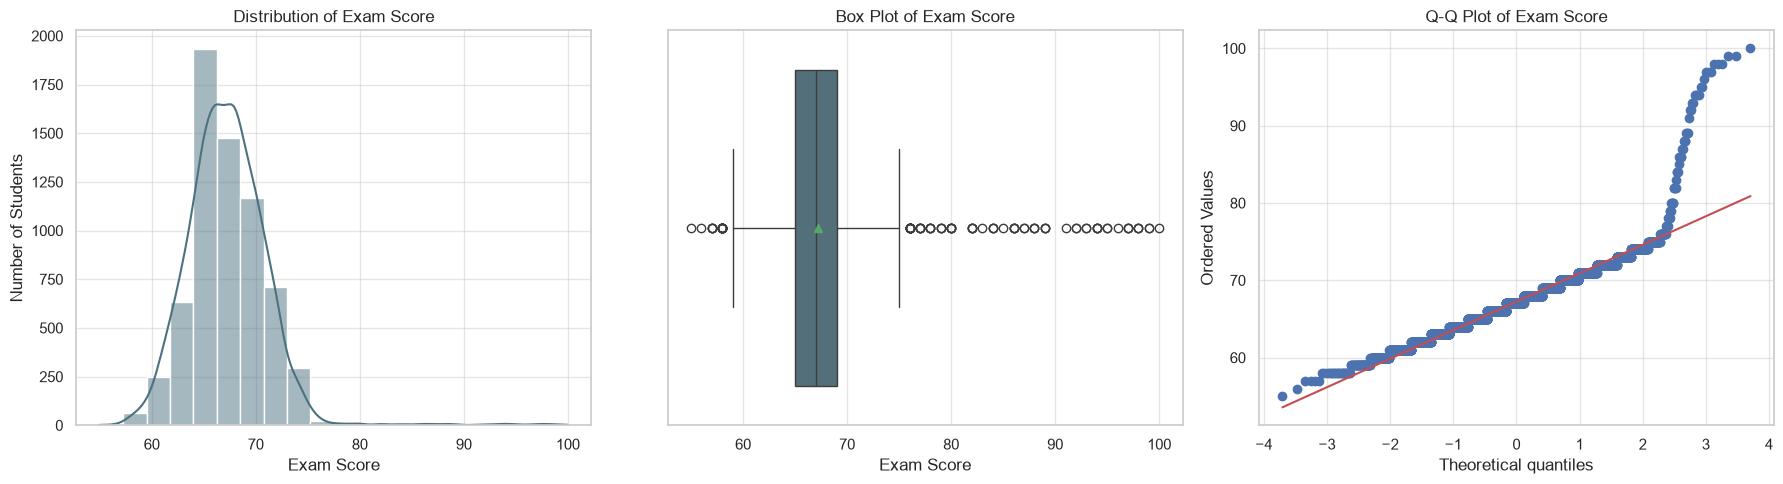

count    6606.00
mean       67.23
std         3.87
min        55.00
25%        65.00
50%        67.00
75%        69.00
max       100.00
Name: Exam_Score, dtype: float64


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['Exam_Score'], bins=20, kde=True, color='#4C7280', ax=axes[0])
axes[0].set(title='Distribution of Exam Score', xlabel='Exam Score', ylabel='Number of Students')

sns.boxplot(x=df['Exam_Score'], color='#4C7280', showmeans=True, ax=axes[1])
axes[1].set(title='Box Plot of Exam Score', xlabel='Exam Score')

stats.probplot(df['Exam_Score'], dist='norm', plot=axes[2])
axes[2].set_title('Q-Q Plot of Exam Score')

plt.tight_layout()
plt.show()

print(df['Exam_Score'].describe().round(2))

In [12]:
k2_stat, p_value = stats.normaltest(df['Exam_Score'])  # D'Agostino-Pearson test
print(f"D'Agostino-Pearson: statistic = {k2_stat:.1f}, p-value = {p_value:.2e}")
print(f"Skewness: {stats.skew(df['Exam_Score']):.2f}")
print(f"Excess kurtosis: {stats.kurtosis(df['Exam_Score']):.2f}")

D'Agostino-Pearson: statistic = 2627.7, p-value = 0.00e+00
Skewness: 1.58
Excess kurtosis: 10.01


**Observations**

- Scores are tightly packed: the standard deviation is about 3.9 points and the middle 50% of students score 65-69.
- The Q-Q plot follows the normal line for the central around 95% of students. The break is at the top: a small group scores 80-100, far above where a normal tail would end. This abrupt jump (not a gradual skew) is why the normality test rejects normality and why skewness and kurtosis are high.
- A normal target is not required for regression, but those few high scorers will be hard to predict and will dominate the large errors later.

### Numerical Features

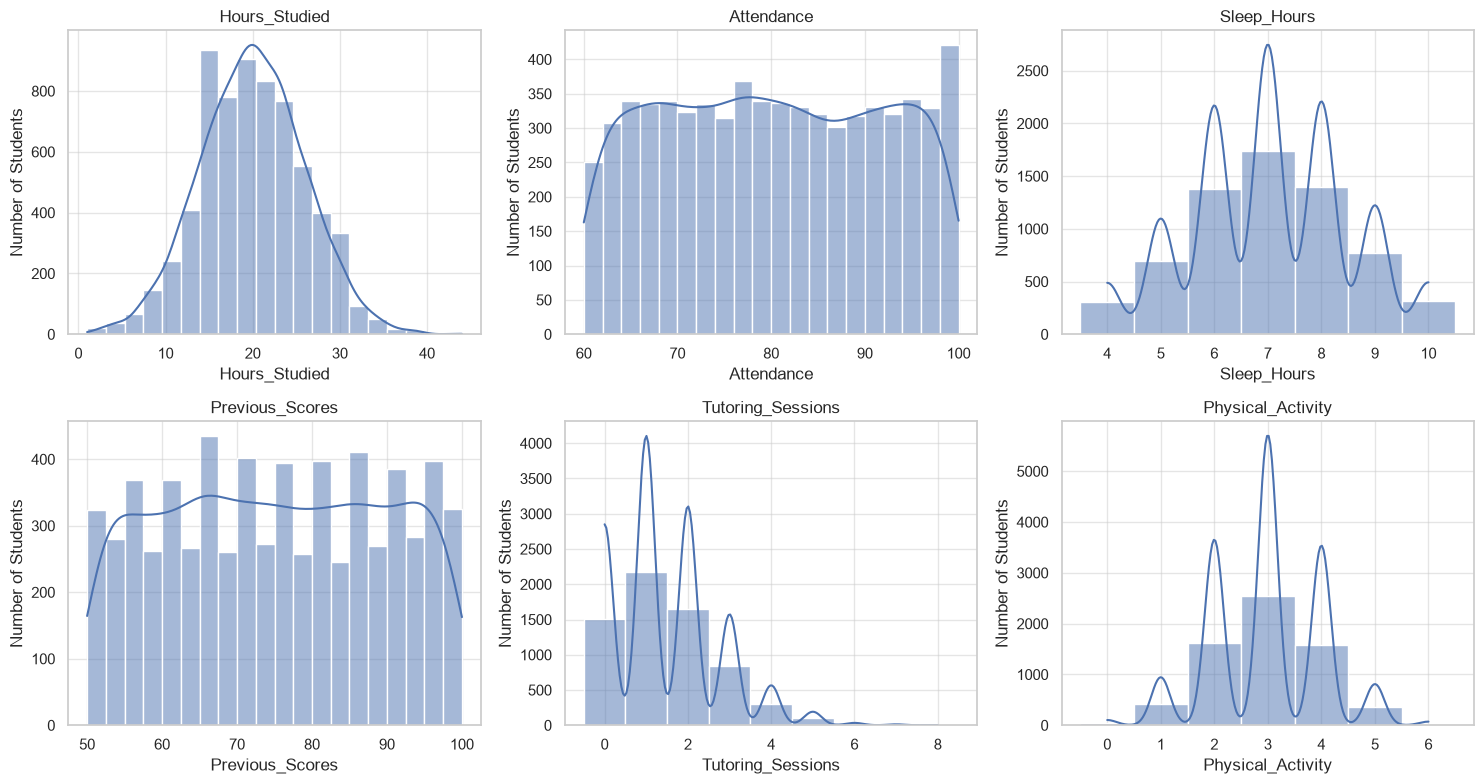

In [13]:
fig, axes = make_grid(len(numerical_cols))
for ax, col in zip(axes, numerical_cols):
    sns.histplot(data=df, x=col, bins=20, discrete=df[col].nunique() <= 10, kde=True, ax=ax)
    ax.set(title=col, ylabel='Number of Students')
plt.tight_layout()
plt.show()

In [14]:
shape_summary = pd.DataFrame({
    'Mean': df[numerical_cols].mean(),
    'Median': df[numerical_cols].median(),
    'Std': df[numerical_cols].std(),
    'Skewness': df[numerical_cols].skew(),
    'Kurtosis': df[numerical_cols].kurt(),
}).round(2)
shape_summary

,Mean,Median,Std,Skewness,Kurtosis
Hours_Studied,19.97,20.0,5.99,0.01,0.02
Attendance,79.97,80.0,11.55,0.01,-1.19
Sleep_Hours,7.03,7.0,1.47,-0.02,-0.50
Previous_Scores,75.07,75.0,14.40,-0.00,-1.19
Tutoring_Sessions,1.49,1.0,1.23,0.81,0.64
Physical_Activity,2.97,3.0,1.03,-0.03,-0.06


**Observations**

- Every feature except `Tutoring_Sessions` is symmetric (|skewness| < 0.5) and its mean is close to its median.
- `Attendance` and `Previous_Scores` have kurtosis around -1.2, the value of a uniform distribution: students are spread evenly over 60-100 % and 50-100 points.
- `Tutoring_Sessions` is mildly right-skewed: most students take 0-2 sessions and a few take up to 8.
- No feature is skewed enough to need a transformation.

#### Outliers

In [15]:
VALID_RANGES = {
    'Hours_Studied':     (0, 168),  # hours per week
    'Attendance':        (0, 100),  # percent
    'Sleep_Hours':       (0, 24),   # hours per night
    'Previous_Scores':   (0, 100),  # score
    'Tutoring_Sessions': (0, 31),   # sessions per month
    'Physical_Activity': (0, 168),  # hours per week
}


def iqr_outliers(data, col):
    q1, q3 = data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    return data[col] < q1 - 1.5 * iqr, data[col] > q3 + 1.5 * iqr


outlier_rows = []
for col in numerical_cols:
    low, high = iqr_outliers(df, col)
    outlier_rows.append({
        'Feature': col,
        'Impossible_Values': (~df[col].between(*VALID_RANGES[col])).sum(),
        'Low_Outliers': low.sum(),
        'High_Outliers': high.sum(),
        'Mean_Score_Low': df.loc[low, 'Exam_Score'].mean(),
        'Mean_Score_High': df.loc[high, 'Exam_Score'].mean(),
        'Mean_Score_Rest': df.loc[~(low | high), 'Exam_Score'].mean(),
    })

pd.DataFrame(outlier_rows).round(2)

,Feature,Impossible_Values,Low_Outliers,High_Outliers,Mean_Score_Low,Mean_Score_High,Mean_Score_Rest
0,Hours_Studied,0,21,22,63.19,73.68,67.22
1,Attendance,0,0,0,NaN,NaN,67.23
2,Sleep_Hours,0,0,0,NaN,NaN,67.23
3,Previous_Scores,0,0,0,NaN,NaN,67.23
4,Tutoring_Sessions,0,0,429,NaN,68.53,67.14
5,Physical_Activity,0,0,0,NaN,NaN,67.23


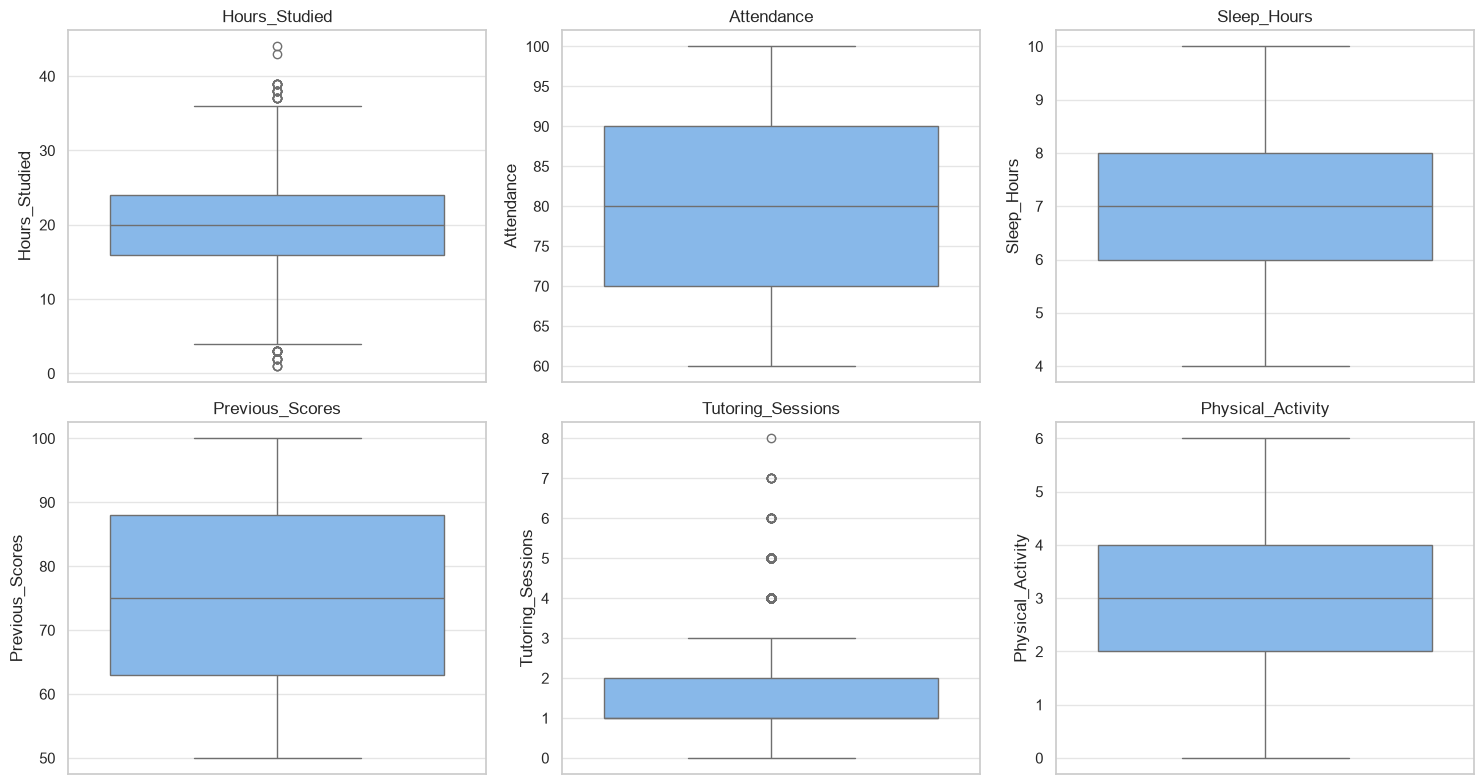

In [16]:
fig, axes = make_grid(len(numerical_cols))
for ax, col in zip(axes, numerical_cols):
    sns.boxplot(data=df, y=col, color='#78b8f9', ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [17]:
df.groupby('Tutoring_Sessions')['Exam_Score'].agg(['count', 'mean']).round(2)

,count,mean
Tutoring_Sessions,,
0,1513,66.49
1,2179,66.98
2,1649,67.57
3,836,67.89
4,301,68.23
5,102,68.75
6,18,71.67
7,7,69.86
8,1,69.00


**Observations**

- No value is outside its physically possible range.
- `Hours_Studied` has 43 IQR outliers (0.65 %), about what a normal distribution produces by chance.
- `Tutoring_Sessions` has 429 high outliers (4-8 sessions). The mean score keeps rising with the number of sessions, so these students follow the general trend instead of breaking it.

**Decision:** all outliers are real, plausible students, so they are kept.

### Categorical Features

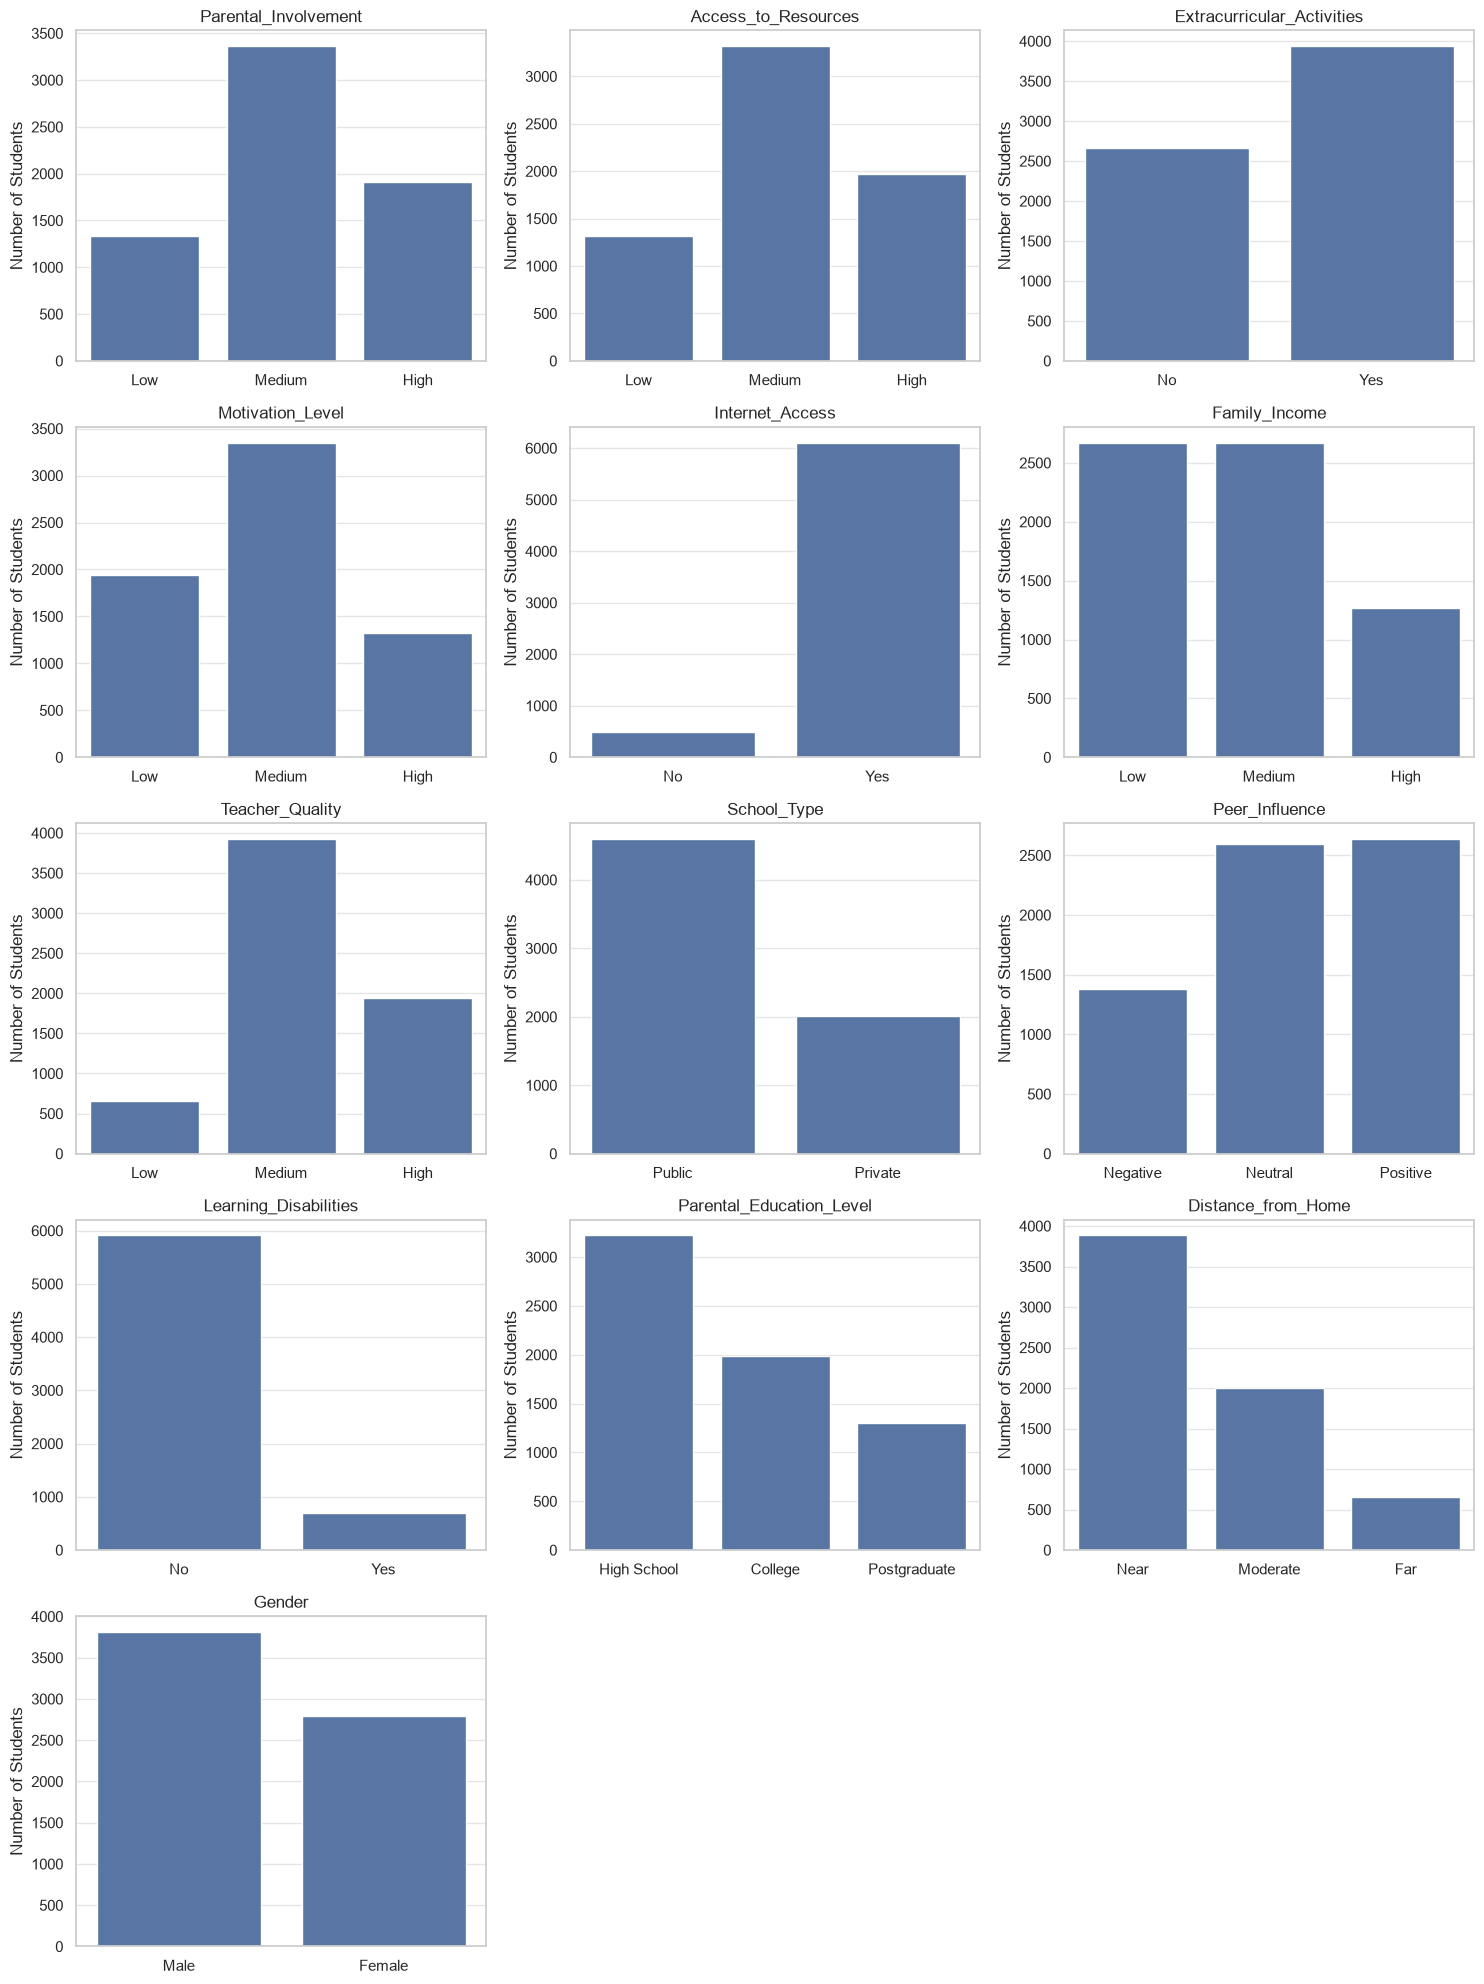

In [18]:
fig, axes = make_grid(len(categorical_cols))
for ax, col in zip(axes, categorical_cols):
    sns.countplot(data=df, x=col, order=CAT_LEVELS[col], ax=ax)
    ax.set(title=col, xlabel='', ylabel='Number of Students')
plt.tight_layout()
plt.show()

In [19]:
category_check = []
for col in categorical_cols:
    counts = df[col].value_counts()
    category_check.append({
        'Feature': col,
        'Unexpected_Labels': sorted(set(counts.index) - set(CAT_LEVELS[col])),
        'Smallest_Level': counts.idxmin(),
        'Smallest_Percent': round(counts.min() / len(df) * 100, 2),
    })

pd.DataFrame(category_check).sort_values('Smallest_Percent').reset_index(drop=True)

,Feature,Unexpected_Labels,Smallest_Level,Smallest_Percent
0,Internet_Access,[],No,7.54
1,Teacher_Quality,[],Low,9.95
2,Distance_from_Home,[],Far,9.96
3,Learning_Disabilities,[],Yes,10.52
4,Family_Income,[],High,19.19
5,Parental_Education_Level,[],Postgraduate,19.75
6,Access_to_Resources,[],Low,19.88
7,Motivation_Level,[],High,19.97
8,Parental_Involvement,[],Low,20.22
9,Peer_Influence,[],Negative,20.84


**Observations**

- Every column contains only its expected labels (no typos or case differences).
- Most three-level features follow a roughly 20 / 50 / 30 % split with `Medium` the most common.
- `Internet_Access` (92.5% Yes) and `Learning_Disabilities` (89.5% No) are imbalanced, but even the smallest level (`Internet_Access = No`, 7.5 %) has about 500 students, so no levels need to be merged.

### Numerical Features vs Exam_Score

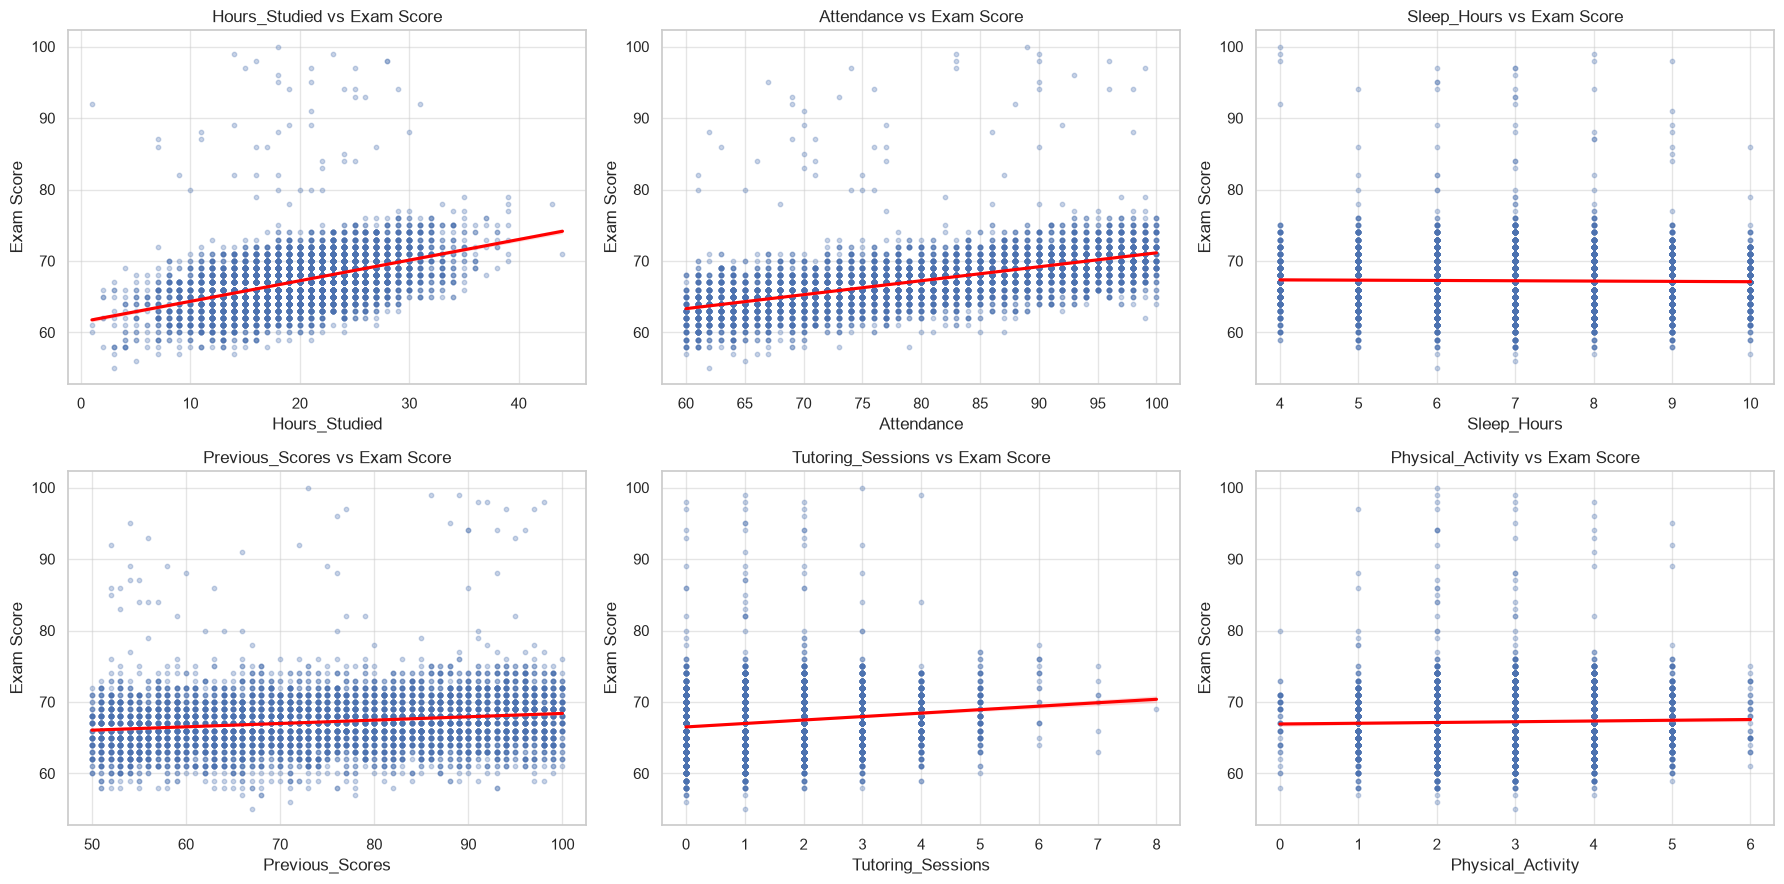

In [20]:
fig, axes = make_grid(len(numerical_cols), cell_size=(6, 4.5))
for ax, col in zip(axes, numerical_cols):
    sns.regplot(data=df, x=col, y='Exam_Score', ax=ax,
                scatter_kws={'alpha': 0.3, 's': 10}, line_kws={'color': 'red'})
    ax.set(title=f'{col} vs Exam Score', ylabel='Exam Score')
plt.tight_layout()
plt.show()

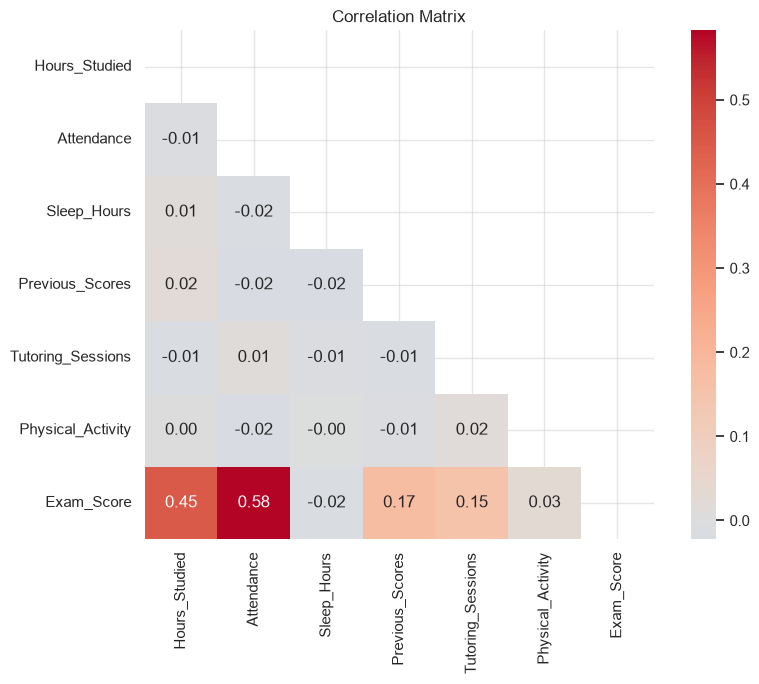

Attendance           0.582
Hours_Studied        0.447
Previous_Scores      0.174
Tutoring_Sessions    0.154
Physical_Activity    0.028
Sleep_Hours         -0.016
Name: Exam_Score, dtype: float64

In [21]:
corr_matrix = df[list(numerical_cols) + ['Exam_Score']].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # hide the upper triangle

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

exam_corr = corr_matrix['Exam_Score'].drop('Exam_Score').sort_values(ascending=False)
exam_corr.round(3)

**Observations**

- `Attendance` (r = 0.58) and `Hours_Studied` (r = 0.45) are by far the strongest linear predictors. Surprisingly, `Previous_Scores` is weak (r = 0.17).
- `Sleep_Hours` and `Physical_Activity` have practically no relationship with the score.
- The features are almost uncorrelated with each other, so there is no multicollinearity.
- All trends are straight lines, so a linear model is a sensible first choice.

### Categorical Features vs Exam_Score

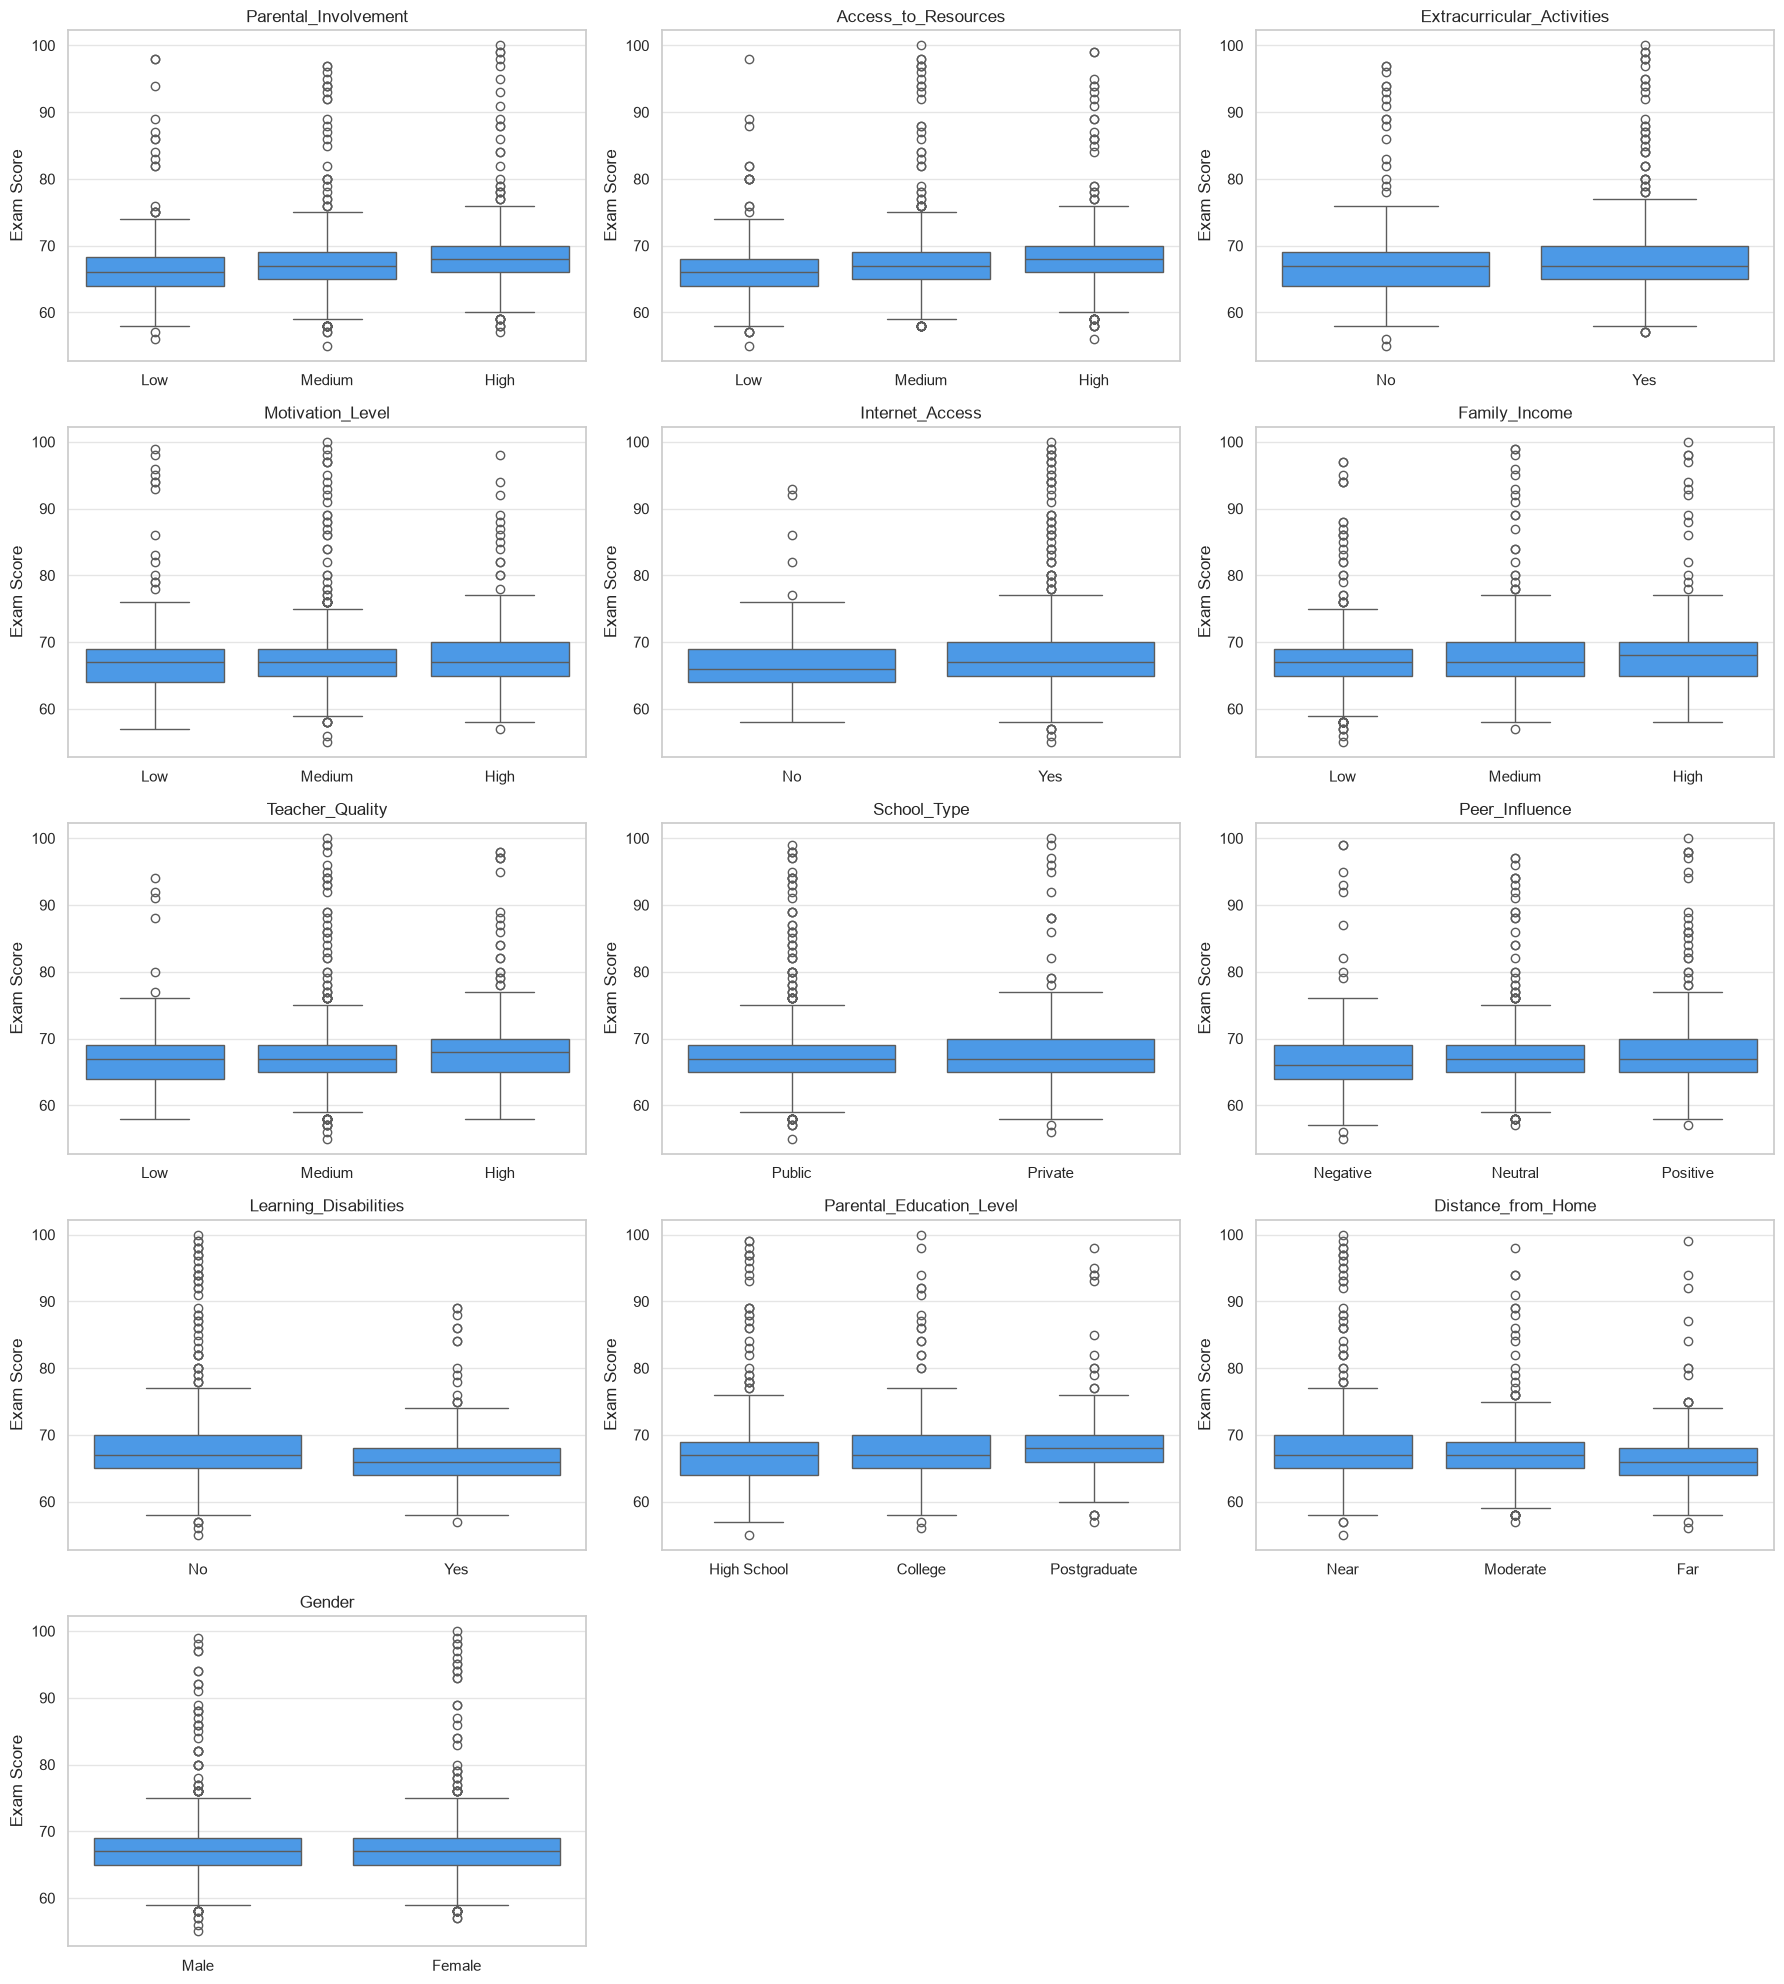

In [22]:
fig, axes = make_grid(len(categorical_cols), cell_size=(6, 4))
for ax, col in zip(axes, categorical_cols):
    sns.boxplot(data=df, x=col, y='Exam_Score', order=CAT_LEVELS[col], color='#3399ff', ax=ax)
    ax.set(title=col, xlabel='', ylabel='Exam Score')
plt.tight_layout()
plt.show()

A one-way ANOVA tests whether the group means differ. Eta squared is the share of score variance explained by the feature, which shows how *large* the difference is, not just whether it exists.

In [23]:
overall_mean = df['Exam_Score'].mean()
ss_total = ((df['Exam_Score'] - overall_mean) ** 2).sum()

anova_rows = []
for col in categorical_cols:
    groups = [group['Exam_Score'] for _, group in df.groupby(col)]
    f_stat, p_value = stats.f_oneway(*groups)
    ss_between = sum(len(g) * (g.mean() - overall_mean) ** 2 for g in groups)
    anova_rows.append({
        'Feature': col,
        'F': round(f_stat, 2),
        'P_Value': p_value,
        'Eta_Squared': round(ss_between / ss_total, 4),
        'Significant': p_value < 0.05,
    })

anova_results = pd.DataFrame(anova_rows).sort_values('Eta_Squared', ascending=False).reset_index(drop=True)
anova_results

,Feature,F,P_Value,Eta_Squared,Significant
0,Access_to_Resources,99.40,2.931422e-43,0.0292,True
1,Parental_Involvement,87.61,2.799222e-38,0.0259,True
2,Parental_Education_Level,37.65,5.513226e-17,0.0113,True
3,Peer_Influence,33.57,3.136320e-15,0.0101,True
4,Family_Income,28.78,3.593386e-13,0.0086,True
5,Distance_from_Home,28.29,5.833509e-13,0.0085,True
6,Motivation_Level,27.14,1.821126e-12,0.0082,True
7,Learning_Disabilities,48.18,4.262935e-12,0.0072,True
8,Teacher_Quality,18.90,6.540816e-09,0.0057,True
9,Extracurricular_Activities,26.88,2.230941e-07,0.0041,True


**Observations**

- 11 of 13 categorical features are significant. `School_Type` and `Gender` show no difference at all.
- Every effect is small. The largest, `Access_to_Resources` and `Parental_Involvement`, each explain only about 3% of the variance, compared with about 34% for `Attendance` alone.
- The ordered features move step by step in the expected direction (Low < Medium < High), which supports encoding them as ordered numbers.

## Feature Engineering

Four features are added by `add_engineered_features` in `src/features.py`.

| Feature | Formula | Idea |
|---|---|---|
| `Study_Efficiency` | Previous_Scores / (Hours_Studied + 1) | Past result per hour of study |
| `Support_Score` | Parental_Involvement (1-3) + Tutoring_Sessions rescaled to 0-3 | Total support |
| `Total_Resources` | Access_to_Resources (1-3) + Internet_Access (0/1) | Available resources |
| `Study_Life_Balance` | Sleep_Hours / (Hours_Studied + 1) | Rest vs workload |

In [24]:
df_engineered = add_engineered_features(df)

compare_cols = ['Hours_Studied', 'Attendance', 'Previous_Scores', 'Sleep_Hours'] + ENGINEERED_FEATURES
df_engineered[compare_cols].corrwith(df_engineered['Exam_Score']).round(3).to_frame('Correlation_with_Exam_Score')

,Correlation_with_Exam_Score
Hours_Studied,0.447
Attendance,0.582
Previous_Scores,0.174
Sleep_Hours,-0.016
Study_Efficiency,-0.244
Support_Score,0.219
Total_Resources,0.181
Study_Life_Balance,-0.313


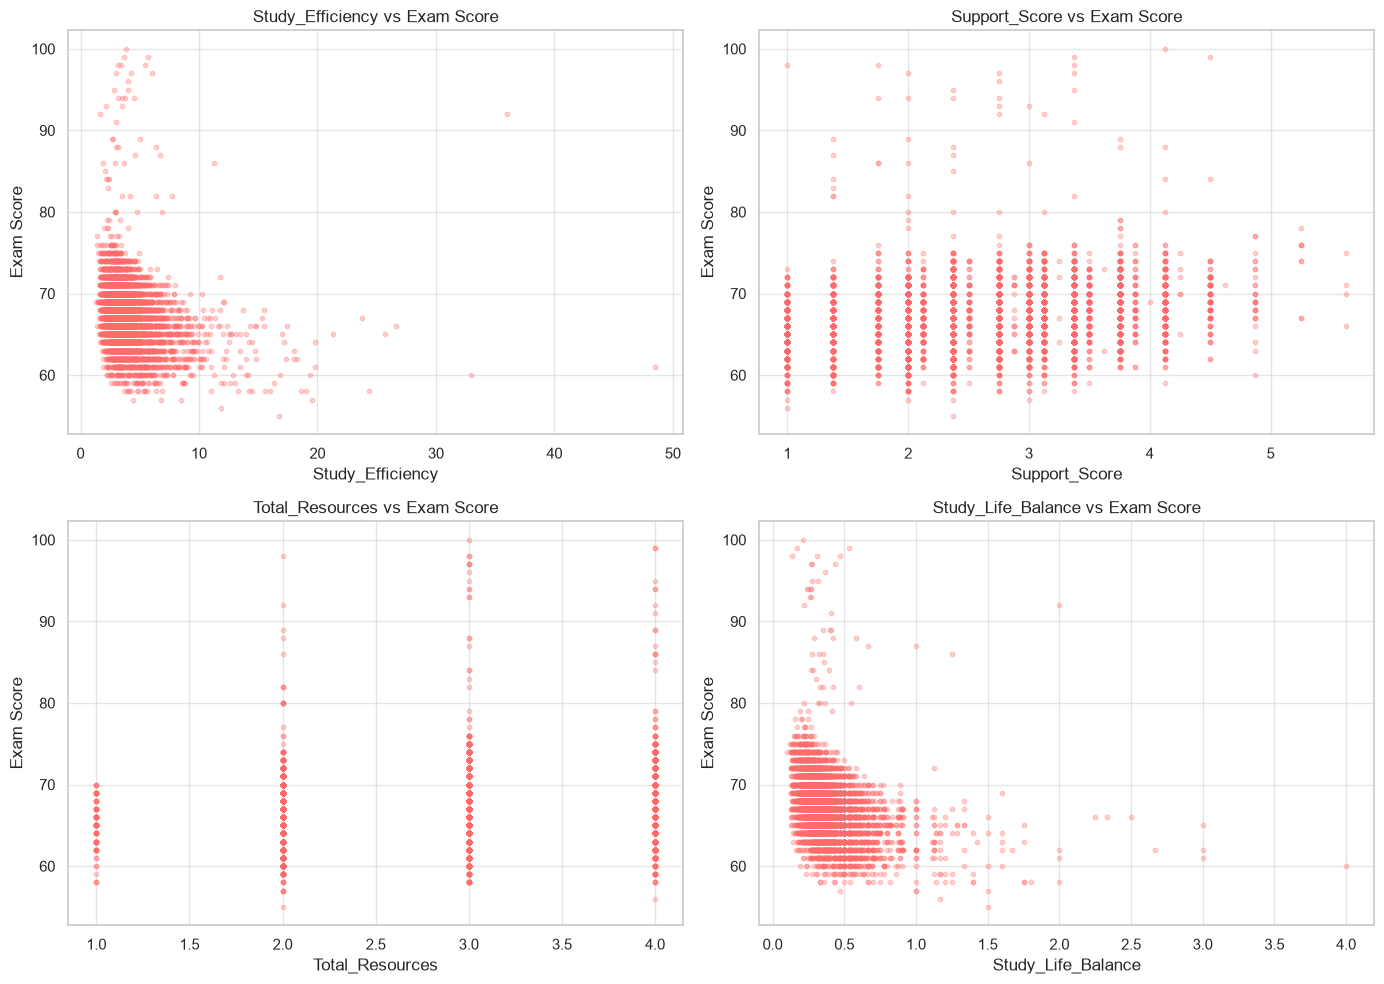

In [25]:
fig, axes = make_grid(len(ENGINEERED_FEATURES), n_cols=2, cell_size=(7, 5))
for ax, feature in zip(axes, ENGINEERED_FEATURES):
    ax.scatter(df_engineered[feature], df_engineered['Exam_Score'], alpha=0.3, s=10, color='#FF6B6B')
    ax.set(xlabel=feature, ylabel='Exam Score', title=f'{feature} vs Exam Score')
plt.tight_layout()
plt.show()

**Observation:** The ratio features `Study_Efficiency` and `Study_Life_Balance` are negatively correlated with the score, mostly because `Hours_Studied` is in the denominator. None of the engineered features beats `Attendance` or `Hours_Studied`, but they are kept as candidates and the model decides how much to use them.

## Modeling

### Train / Test Split

In [26]:
X = df.drop(columns='Exam_Score')
y = df['Exam_Score']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape[0]} students | Test: {X_test.shape[0]} students | Raw features: {X.shape[1]}")
print(f"Mean score: train = {y_train.mean():.2f}, test = {y_test.mean():.2f}")

Train: 5284 students | Test: 1322 students | Raw features: 19
Mean score: train = 67.26, test = 67.10


### Preprocessing Pipeline

- **Numerical** (6 original + 4 engineered): median imputation, then standard scaling
- **Ordinal** (natural order, e.g. Low < Medium < High): most-frequent imputation, ordinal encoding, scaling
- **Nominal** (no order, e.g. Gender): most-frequent imputation, one-hot encoding

In [27]:
ORDINAL_FEATURES = ['Parental_Involvement', 'Access_to_Resources', 'Motivation_Level', 'Family_Income',
                    'Teacher_Quality', 'Parental_Education_Level', 'Distance_from_Home', 'Peer_Influence']
NOMINAL_FEATURES = ['Extracurricular_Activities', 'Internet_Access', 'School_Type',
                    'Learning_Disabilities', 'Gender']
NUMERIC_FEATURES = list(numerical_cols) + ENGINEERED_FEATURES

assert set(ORDINAL_FEATURES) | set(NOMINAL_FEATURES) == set(categorical_cols)

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

ordinal_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(categories=[CAT_LEVELS[col] for col in ORDINAL_FEATURES])),
    ('scaler', StandardScaler()),
])

nominal_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='if_binary', handle_unknown='ignore')),
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, NUMERIC_FEATURES),
    ('ord', ordinal_transformer, ORDINAL_FEATURES),
    ('nom', nominal_transformer, NOMINAL_FEATURES),
], verbose_feature_names_out=False)


def build_pipeline(model):
    """Feature engineering -> preprocessing -> model."""
    return Pipeline([
        ('feature_engineering', FunctionTransformer(add_engineered_features)),
        ('preprocessing', clone(preprocessor)),
        ('model', model),
    ])


build_pipeline(LinearRegression())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('preprocessing', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...00249067E4720>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, def

In [28]:
prep = build_pipeline(LinearRegression())[:-1].fit(X_train)
X_train_prepared = pd.DataFrame(prep.transform(X_train),
                                columns=prep.named_steps['preprocessing'].get_feature_names_out())
print(f"Raw: {X_train.shape} -> Prepared: {X_train_prepared.shape}")
X_train_prepared.head().round(3)

Raw: (5284, 19) -> Prepared: (5284, 23)


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Study_Efficiency,Support_Score,Total_Resources,Study_Life_Balance,Parental_Involvement,Access_to_Resources,Motivation_Level,Family_Income,Teacher_Quality,Parental_Education_Level,Distance_from_Home,Peer_Influence,Extracurricular_Activities_Yes,Internet_Access_Yes,School_Type_Public,Learning_Disabilities_Yes,Gender_Male
0,-1.510,-0.433,1.346,0.137,-0.398,-0.945,1.162,0.877,-0.043,1.911,1.319,1.286,0.135,1.623,1.345,0.400,0.740,-0.253,1.0,0.0,0.0,1.0,1.0
1,-2.013,-0.607,0.665,0.206,-1.210,0.026,2.240,-0.773,1.308,2.615,-0.123,1.286,1.574,0.277,1.345,-0.887,-0.752,-1.570,0.0,1.0,0.0,0.0,1.0
2,-1.677,-0.346,-2.056,-0.490,-0.398,2.939,1.050,-0.323,-1.393,-0.049,-0.123,-1.592,0.135,1.623,-1.996,0.400,-0.752,-0.253,0.0,1.0,0.0,0.0,1.0
3,-0.002,0.347,-0.015,-0.072,-0.398,0.026,-0.223,-1.523,-1.393,-0.203,-1.565,-1.592,-1.304,1.623,-0.326,1.687,-0.752,-0.253,0.0,1.0,1.0,0.0,0.0
4,-0.002,-1.560,-2.056,1.599,-0.398,0.997,0.324,-0.323,-0.043,-0.927,-0.123,-0.153,1.574,1.623,-1.996,-0.887,-0.752,-1.570,0.0,1.0,1.0,0.0,1.0


### Baseline Models

In [29]:
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(max_depth=10, random_state=RANDOM_STATE),
    'Neural Network': MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=500, early_stopping=True, random_state=RANDOM_STATE),
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {'r2': 'r2', 'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error'}


def evaluate(pipeline):
    cv_scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    return {
        'CV_R2': cv_scores['test_r2'].mean(),
        'CV_R2_std': cv_scores['test_r2'].std(),
        'CV_RMSE': -cv_scores['test_rmse'].mean(),
        'R2': r2_score(y_test, y_pred),
        'RMSE': root_mean_squared_error(y_test, y_pred),
        'MAE': mean_absolute_error(y_test, y_pred),
        'predictions': y_pred,
        'pipeline': pipeline,
    }


results = {}
for name, model in models.items():
    results[name] = evaluate(build_pipeline(model))
    r = results[name]
    print(f"{name:18s}: CV R^2 = {r['CV_R2']:.4f} | CV RMSE = {r['CV_RMSE']:.3f}")

Linear Regression : CV R^2 = 0.7148 | CV RMSE = 2.090
Decision Tree     : CV R^2 = 0.1113 | CV RMSE = 3.688
Neural Network    : CV R^2 = 0.6450 | CV RMSE = 2.337


### Hyperparameter Tuning

`GridSearchCV` tunes the two models that have important hyperparameters. Linear Regression has none, so it is not tuned.

- **Decision Tree:** `max_depth` and `min_samples_leaf` limit how much the tree can memorise noise.
- **Neural Network:** layer sizes, L2 penalty `alpha` and the learning rate.

In [30]:
param_grids = {
    'Decision Tree': {
        'model__max_depth': [3, 5, 7, 10, None],
        'model__min_samples_leaf': [1, 10, 30, 50],
    },
    'Neural Network': {
        'model__hidden_layer_sizes': [(50,), (100, 50)],
        'model__alpha': [0.0001, 0.01, 1.0],
        'model__learning_rate_init': [0.001, 0.01],
    },
}

searches = {}
for name, grid in param_grids.items():
    search = GridSearchCV(build_pipeline(clone(models[name])), grid, cv=cv, scoring='r2', n_jobs=-1)
    search.fit(X_train, y_train)
    searches[name] = search
    print(f"{name}: best CV R\u00b2 = {search.best_score_:.4f} with {search.best_params_}")

    results[f'{name} (tuned)'] = evaluate(search.best_estimator_)

Decision Tree: best CV R² = 0.5300 with {'model__max_depth': 10, 'model__min_samples_leaf': 30}
Neural Network: best CV R² = 0.6542 with {'model__alpha': 1.0, 'model__hidden_layer_sizes': (100, 50), 'model__learning_rate_init': 0.001}


### Model Comparison

The best model is chosen by **cross-validated R&sup2;**, not test R&sup2;.

In [31]:
comparison_df = pd.DataFrame([{
    'Model': name,
    'CV R^2': r['CV_R2'],
    'CV R^2 Std': r['CV_R2_std'],
    'Test R^2': r['R2'],
    'Test RMSE': r['RMSE'],
    'Test MAE': r['MAE'],
} for name, r in results.items()]).sort_values('CV R^2', ascending=False).reset_index(drop=True)

best_model = comparison_df.loc[0, 'Model']
best = results[best_model]
print(f"Best model: {best_model}")
comparison_df.round(3)

Best model: Linear Regression


,Model,CV R^2,CV R^2 Std,Test R^2,Test RMSE,Test MAE
0,Linear Regression,0.715,0.074,0.826,1.518,0.415
1,Neural Network (tuned),0.654,0.079,0.763,1.770,0.852
2,Neural Network,0.645,0.064,0.740,1.856,0.942
3,Decision Tree (tuned),0.530,0.045,0.622,2.234,1.406
4,Decision Tree,0.111,0.048,0.163,3.328,1.626


Linear Regression has the highest CV R&sup2; and also the lowest test errors. Tuning helps the Decision Tree a lot (0.11 to 0.53) by stopping it from memorising noise, but neither tuned model reaches the linear one.

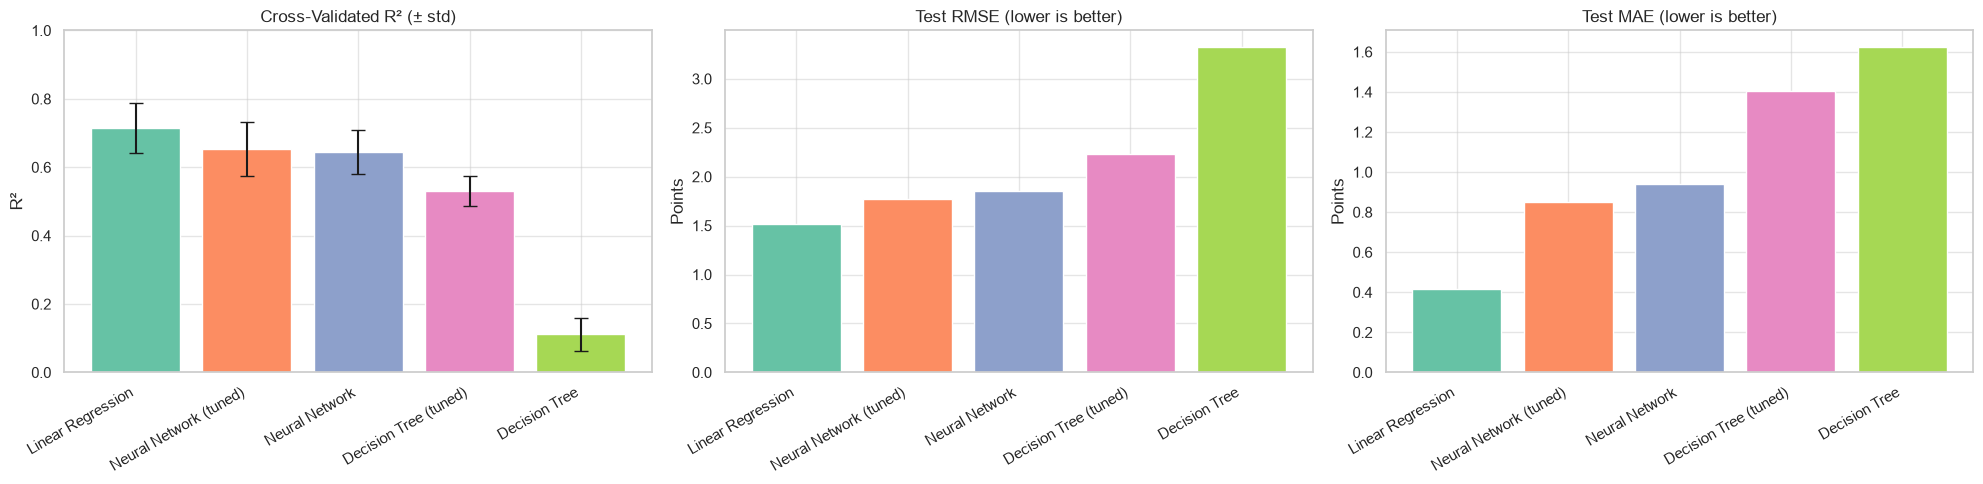

In [32]:
colors = sns.color_palette('Set2', len(comparison_df))
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].bar(comparison_df['Model'], comparison_df['CV R^2'], yerr=comparison_df['CV R^2 Std'], capsize=5, color=colors)
axes[0].set(title='Cross-Validated R\u00b2 (\u00b1 std)', ylabel='R\u00b2', ylim=[0, 1])
axes[1].bar(comparison_df['Model'], comparison_df['Test RMSE'], color=colors)
axes[1].set(title='Test RMSE (lower is better)', ylabel='Points')
axes[2].bar(comparison_df['Model'], comparison_df['Test MAE'], color=colors)
axes[2].set(title='Test MAE (lower is better)', ylabel='Points')

for ax in axes:
    ax.tick_params(axis='x', rotation=30)
    plt.setp(ax.get_xticklabels(), ha='right')
plt.tight_layout()
plt.show()

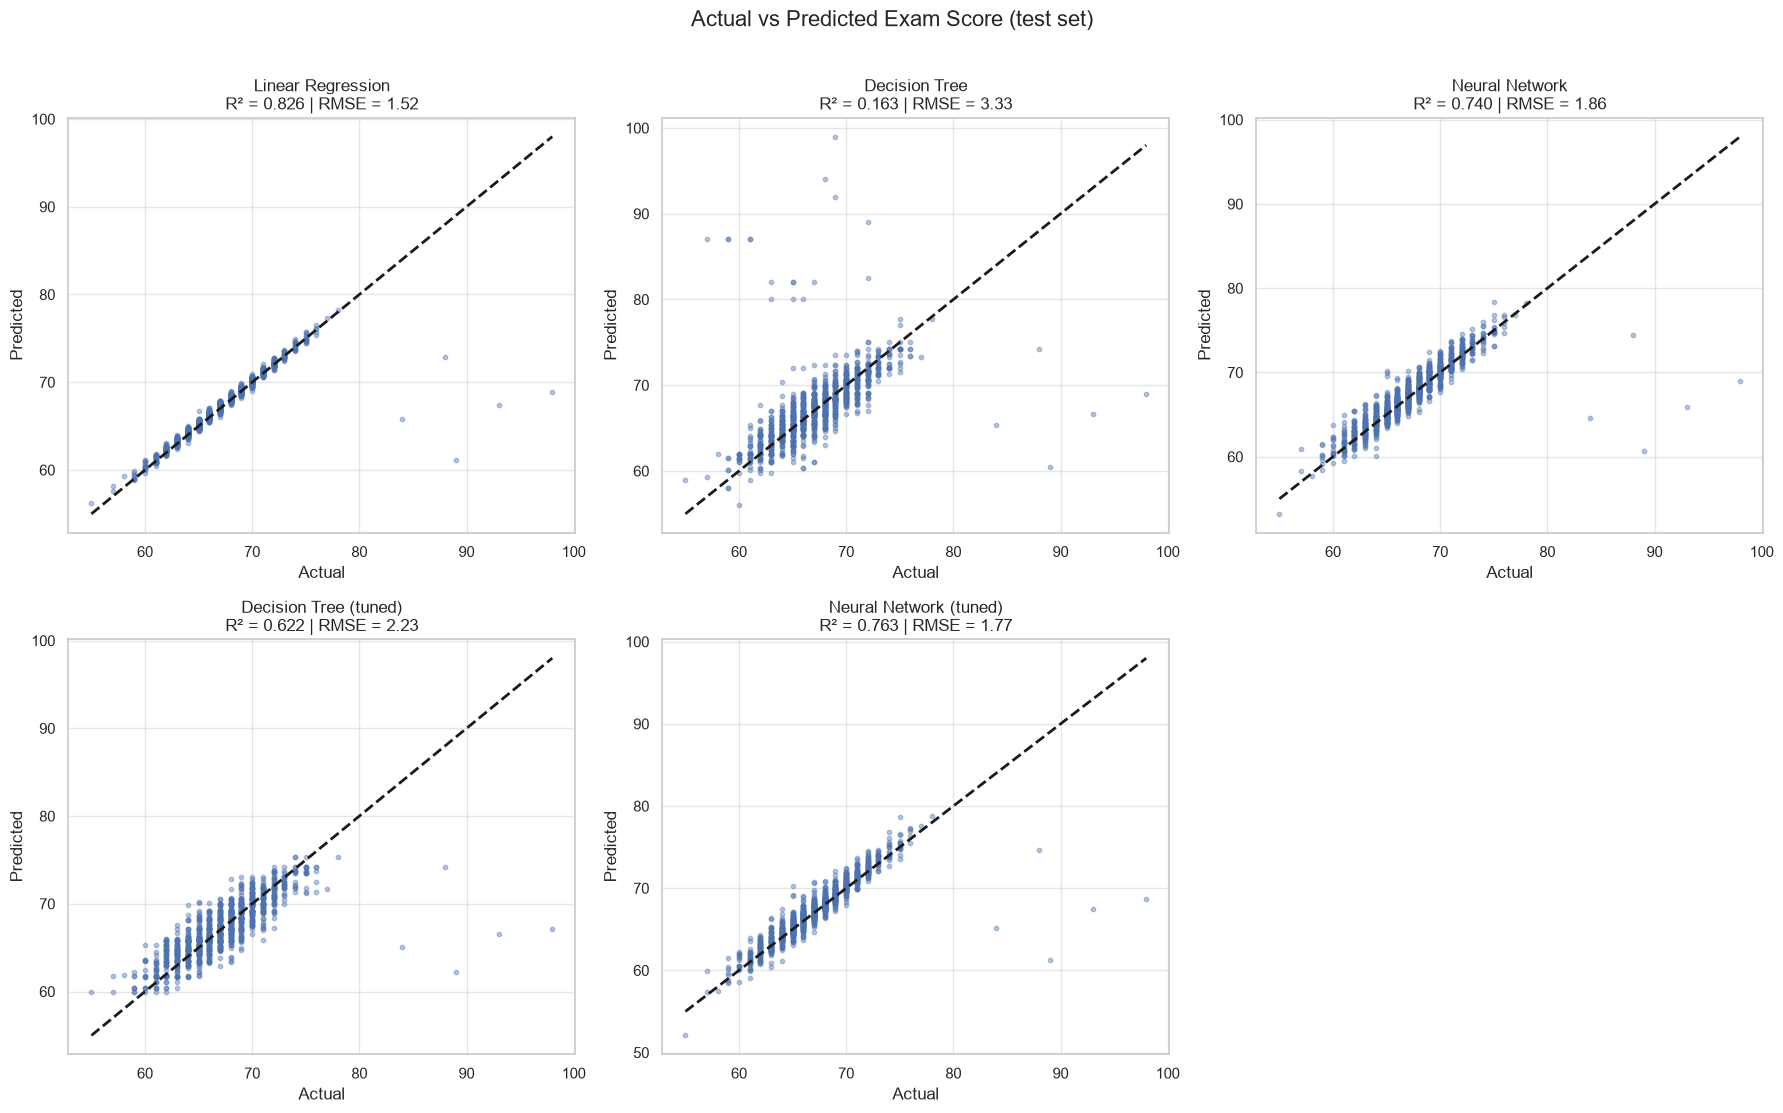

In [33]:
fig, axes = make_grid(len(results), cell_size=(6, 5.5))
for ax, (name, r) in zip(axes, results.items()):
    ax.scatter(y_test, r['predictions'], alpha=0.4, s=10)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
    ax.set(xlabel='Actual', ylabel='Predicted', title=f"{name}\nR\u00b2 = {r['R2']:.3f} | RMSE = {r['RMSE']:.2f}")
plt.suptitle('Actual vs Predicted Exam Score (test set)', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

### Best Model Diagnostics

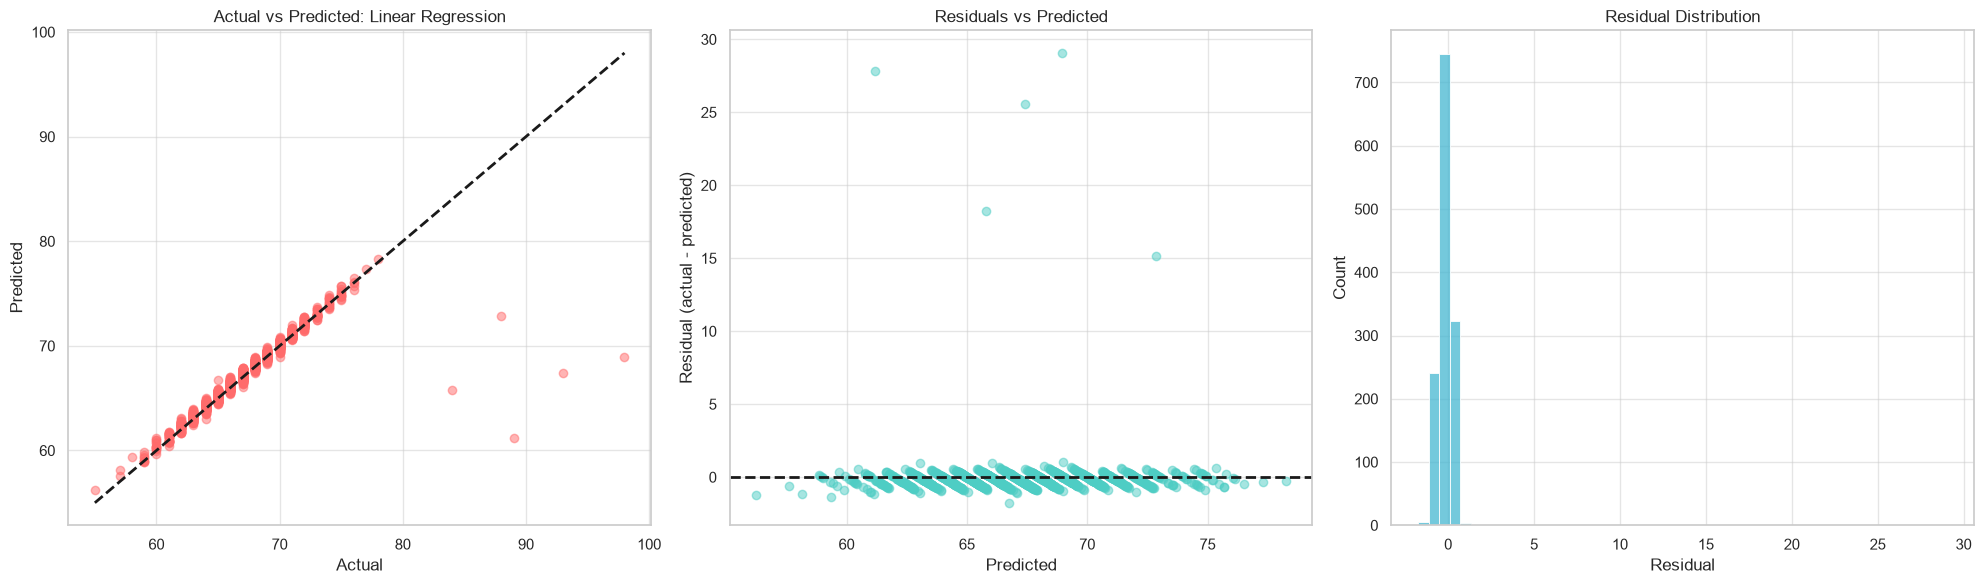

Median absolute error: 0.29 points
Within ±1 point:  98.7% of test students
Within ±2 points: 99.6% of test students
Largest under-prediction: 29.1 points


In [34]:
residuals = y_test - best['predictions']  # positive = student scored higher than predicted

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
axes[0].scatter(y_test, best['predictions'], alpha=0.5, color='#FF6B6B')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
axes[0].set(xlabel='Actual', ylabel='Predicted', title=f'Actual vs Predicted: {best_model}')

axes[1].scatter(best['predictions'], residuals, alpha=0.5, color='#4ECDC4')
axes[1].axhline(0, color='k', linestyle='--', lw=2)
axes[1].set(xlabel='Predicted', ylabel='Residual (actual - predicted)', title='Residuals vs Predicted')

sns.histplot(residuals, bins=50, color='#45B7D1', ax=axes[2])
axes[2].set(xlabel='Residual', title='Residual Distribution')
plt.tight_layout()
plt.show()

abs_residuals = residuals.abs()
print(f"Median absolute error: {abs_residuals.median():.2f} points")
print(f"Within \u00b11 point:  {(abs_residuals <= 1).mean() * 100:.1f}% of test students")
print(f"Within \u00b12 points: {(abs_residuals <= 2).mean() * 100:.1f}% of test students")
print(f"Largest under-prediction: {residuals.max():.1f} points")

**Observation:** Almost all residuals sit in a narrow band around zero, with no curve or funnel shape, so the linear model fits the bulk of students well. The large errors are all positive: students who scored far *higher* than predicted. These are the same high scorers seen in the Q-Q plot.

### Feature Importance

**Permutation importance** of the best model on the test set: how much R&sup2; drops when one original column is shuffled.

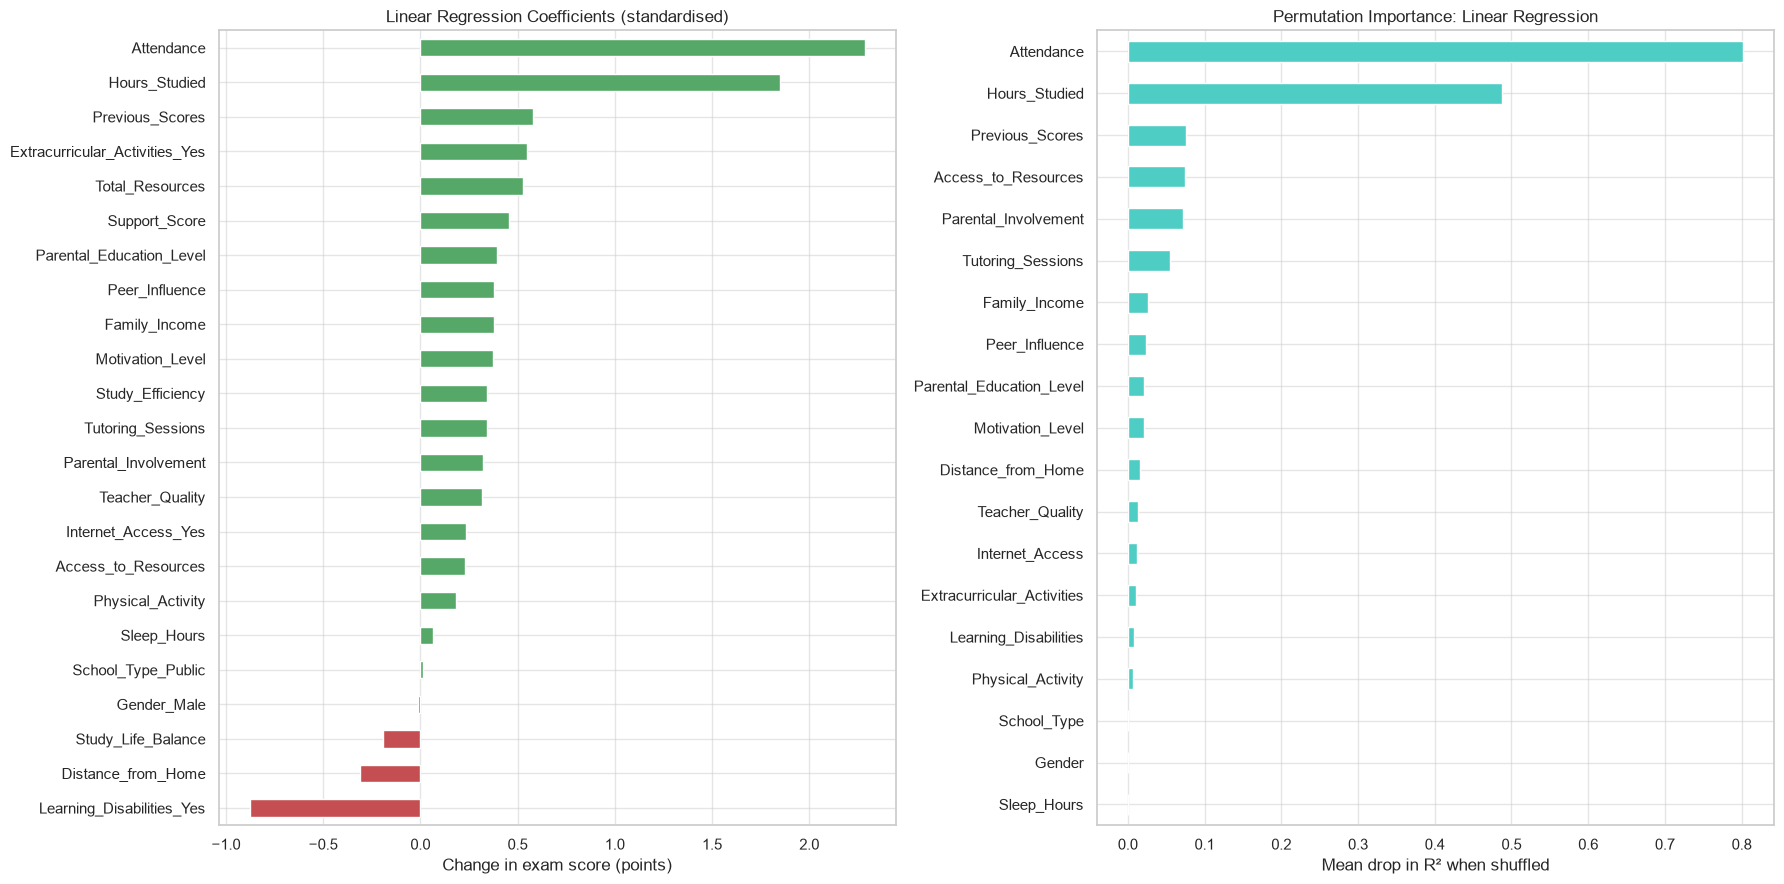

Attendance                  0.8020
Hours_Studied               0.4881
Previous_Scores             0.0759
Access_to_Resources         0.0751
Parental_Involvement        0.0724
Tutoring_Sessions           0.0544
Family_Income               0.0263
Peer_Influence              0.0241
Parental_Education_Level    0.0209
Motivation_Level            0.0209
dtype: float64

In [35]:
lr_pipeline = results['Linear Regression']['pipeline']
coefficients = pd.Series(lr_pipeline.named_steps['model'].coef_,
                         index=lr_pipeline.named_steps['preprocessing'].get_feature_names_out()).sort_values()

perm = permutation_importance(best['pipeline'], X_test, y_test, scoring='r2',
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
perm_importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(18, 9))
coefficients.plot.barh(ax=axes[0], color=np.where(coefficients > 0, '#55A868', '#C44E52'))
axes[0].set(title='Linear Regression Coefficients (standardised)', xlabel='Change in exam score (points)')
perm_importance.plot.barh(ax=axes[1], color='#4ECDC4')
axes[1].set(title=f'Permutation Importance: {best_model}', xlabel='Mean drop in R\u00b2 when shuffled')
plt.tight_layout()
plt.show()

perm_importance.sort_values(ascending=False).head(10).round(4)

## Controllable vs Background Factors

To compare all features on the same scale (exam points), each feature gets a **score gap**:

- Numerical: mean score of the top 25 % of students minus the bottom 25 %
- Categorical: mean score of the best level minus the worst level

In [36]:
def score_gap(col):
    """Difference in mean Exam_Score between the high and low end of a feature."""
    if col in numerical_cols:
        q1, q3 = df[col].quantile([0.25, 0.75])
        return df.loc[df[col] >= q3, 'Exam_Score'].mean() - df.loc[df[col] <= q1, 'Exam_Score'].mean()
    group_means = df.groupby(col)['Exam_Score'].mean()
    return group_means.max() - group_means.min()


CONTROLLABLE = ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Tutoring_Sessions', 'Physical_Activity',
                'Motivation_Level', 'Extracurricular_Activities']

score_gaps = pd.DataFrame({'Score_Gap': [score_gap(col) for col in X.columns]}, index=X.columns)
score_gaps['Type'] = np.where(score_gaps.index.isin(CONTROLLABLE), 'Controllable', 'Background')
score_gaps = score_gaps.sort_values('Score_Gap', ascending=False).round(2)
display(score_gaps)
score_gaps.groupby('Type')['Score_Gap'].mean().round(2)

,Score_Gap,Type
Attendance,5.79,Controllable
Hours_Studied,4.20,Controllable
Access_to_Resources,1.89,Background
Previous_Scores,1.78,Background
Parental_Involvement,1.76,Background
Parental_Education_Level,1.09,Background
Learning_Disabilities,1.07,Background
Distance_from_Home,1.05,Background
Peer_Influence,1.05,Background
Tutoring_Sessions,1.02,Controllable


Type
Background      1.04
Controllable    1.80
Name: Score_Gap, dtype: float64

`Previous_Scores`, `Peer_Influence`, `Teacher_Quality` and `Internet_Access` are counted as background factors because a student cannot change them in the short term.

## Unexpected Patterns: Students the Model Cannot Explain


In [37]:
cv_predictions = cross_val_predict(clone(best['pipeline']), X, y, cv=cv)
cv_residuals = y - cv_predictions

UNEXPLAINED_THRESHOLD = 5  # points above prediction
is_unexplained = cv_residuals > UNEXPLAINED_THRESHOLD
unexplained = df.loc[is_unexplained].assign(Predicted=cv_predictions[is_unexplained].round(1),
                                           Residual=cv_residuals[is_unexplained].round(1))

print(f"{is_unexplained.sum()} students ({is_unexplained.mean() * 100:.1f}%) scored "
      f"{unexplained['Residual'].min():.0f}-{unexplained['Residual'].max():.0f} points above their prediction")
print(f"Largest over-prediction anywhere: {-cv_residuals.min():.1f} points")
unexplained.sort_values('Residual', ascending=False).head(10)

49 students (0.7%) scored 15-30 points above their prediction
Largest over-prediction anywhere: 6.3 points


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score,Predicted,Residual
529,15,83,Medium,Medium,No,7,97,Medium,Yes,2,Low,High,Private,Neutral,2,No,High School,Near,Female,97,66.9,30.1
2424,23,83,High,High,Yes,4,89,Low,Yes,1,Medium,Medium,Public,Negative,3,No,High School,Far,Male,99,69.1,29.9
919,21,74,High,Medium,No,6,94,Medium,Yes,1,Low,High,Public,Positive,1,No,High School,Near,Male,97,67.5,29.5
6392,16,83,Low,Medium,Yes,8,92,Low,Yes,2,High,High,Public,Positive,4,No,Postgraduate,Near,Female,98,68.9,29.1
94,18,89,High,Medium,Yes,4,73,Medium,Yes,3,High,Medium,Private,Positive,2,No,College,Near,Female,100,71.4,28.6
3578,14,90,High,High,Yes,8,86,Medium,Yes,4,Medium,Medium,Private,Negative,2,No,High School,Near,Female,99,70.5,28.5
4296,21,67,Medium,Medium,Yes,6,88,Medium,Yes,1,Low,Medium,Private,Positive,5,No,Postgraduate,Near,Female,95,66.6,28.4
217,19,70,Medium,Low,No,7,54,High,Yes,0,Medium,Medium,Public,Positive,2,Yes,High School,Moderate,Male,89,61.2,27.8
3456,18,93,Medium,Medium,No,7,76,Low,Yes,2,Medium,Medium,Private,Neutral,4,No,High School,Near,Female,96,68.6,27.4
4778,1,88,Medium,High,Yes,4,72,High,Yes,3,Medium,Medium,Private,Negative,2,No,College,Near,Male,92,64.7,27.3


In [38]:
# Do these students differ from everyone else on the recorded features?
pd.DataFrame({
    'Unexplained': df.loc[is_unexplained, numerical_cols].mean(),
    'Everyone_Else': df.loc[~is_unexplained, numerical_cols].mean(),
}).round(2)

,Unexplained,Everyone_Else
Hours_Studied,19.27,19.98
Attendance,78.49,79.99
Sleep_Hours,6.86,7.03
Previous_Scores,73.18,75.08
Tutoring_Sessions,1.39,1.49
Physical_Activity,2.63,2.97


## Conclusions

**1. Which factors matter most?**

`Attendance` and `Hours_Studied` dominate every view: correlation (r = 0.58 and 0.45), permutation importance (R&sup2; drops of 0.80 and 0.49) and score gap (5.8 and 4.2 points). `Previous_Scores` is surprisingly weak (r = 0.17). `Gender` and `School_Type` have no effect.

**2. Controllable vs background.**

The two biggest levers are controllable. Every background factor shifts the score by under 2 points, led by `Access_to_Resources` (1.9) and `Parental_Involvement` (1.8). Sleep and physical activity show no link at all.

**3. How well can we predict?**

| Model | CV R&sup2; (mean &plusmn; std) | Test R&sup2; | Test RMSE | Test MAE |
|---|---|---|---|---|
| **Linear Regression** | **0.715 &plusmn; 0.074** | **0.826** | **1.52** | **0.42** |
| Neural Network (tuned) | 0.654 &plusmn; 0.079 | 0.763 | 1.77 | 0.85 |
| Neural Network | 0.645 &plusmn; 0.064 | 0.740 | 1.86 | 0.94 |
| Decision Tree (tuned) | 0.530 &plusmn; 0.045 | 0.622 | 2.23 | 1.41 |
| Decision Tree | 0.111 &plusmn; 0.048 | 0.163 | 3.33 | 1.63 |

- Linear Regression wins because the score behaves like an additive sum of effects. Trees approximate straight lines with steps, and the neural network needs more data to match a simple linear rule.
- 98.7 % of test students are predicted within &plusmn;1 point. R&sup2; and RMSE are held back by a few very large under-predictions (up to 29 points).
- The test R&sup2; (0.83) is above the CV mean (0.71) but within the fold-to-fold spread: this test split happens to contain fewer of the extreme high scorers. There is no sign of overfitting.

**4. Unexpected patterns.**

- One record had an impossible score of 101 and was removed.
- 49 students (0.7 %) score 15-30 points above their prediction, while no student scores more than about 6 points *below* it. Their recorded features look like everyone else's, so something outside the dataset explains their results.

**Recommendations for educators:** use the model to flag students with a low predicted score early, and focus support on attendance and weekly study hours, the two largest controllable levers.

**Limitations:** the data is observational, so these are associations, not proven causes. The model also cannot foresee the small group of unexpectedly high scorers.

## Save the Model

In [39]:
os.makedirs(os.path.dirname(MODEL_PATH), exist_ok=True)
joblib.dump(best['pipeline'], MODEL_PATH)
print(f"Saved '{best_model}' pipeline to {MODEL_PATH}")

# Sanity check: reload and predict one raw test student
reloaded = joblib.load(MODEL_PATH)
print(f"Predicted: {reloaded.predict(X_test.iloc[[0]])[0]:.1f} | Actual: {y_test.iloc[0]}")

Saved 'Linear Regression' pipeline to ../models/best_model.pkl
Predicted: 66.0 | Actual: 66
